In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl.analysis import runs as R, models as M, data as D
import src.rl.evaluate_critics as ec

R.set_path_mappings([("/rds/general/user/jormond/home/projects/ai_clinician",
                      "/home/jake/Documents/AI_Clinician/models")])

[('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

In [2]:
ALPHA = 0.029
sarsa_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds"            # final health-score SARSA critics (early stopped), seeds 0-4
sarsa_terminal_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/five_seeds"   # final terminal-reward SARSA critics (early stopped), seeds 0-4
cql_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/alpha_sweep"              # alpha sweep folder, as in the WIS notebook
critics_dir = "/home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response"
os.makedirs(critics_dir, exist_ok=True)

is_alpha = lambda r: np.isclose(float(r.get("cql_alpha")), ALPHA)
sarsa_models = M.load_study_models(R.make_study(sarsa_dir, family="sarsa"))
sarsa_terminal_models = M.load_study_models(R.make_study(sarsa_terminal_dir, family="sarsa"))
cql_models = M.load_study_models(R.make_study(cql_dir, family="cql", group_by=("cql_alpha",), include=is_alpha))
store = D.DataStore(keep=("val", "test"))

  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/five_seeds:
    vaso_reward_coefficient: saved=0.01 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic)
  loaded LoadedModel(seed 3: critic)
  loaded LoadedModel(seed 4: critic)
  overrides applied under /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/terminal_only/five_seeds:
    vaso_reward_coefficient: saved=0.2 -> used=0.0  [rule vaso_reward_gate: add_reward_to_vaso_dosing is False]  seeds=[0, 1, 2, 3, 4]
  loaded LoadedModel(seed 0: critic)
  loaded LoadedModel(seed 1: critic)
  loaded LoadedModel(seed 2: critic)
  loaded LoadedModel(s

In [7]:
m0 = next(iter(next(iter(sarsa_models.values())).values()))
p = store.processor(m0, "test")
D.n_rows(p), len(np.unique(D.trajectory_ids(p)))

(116662, 310)

In [14]:
critics = {"SARSA health score": sarsa_models,
           "SARSA terminal": sarsa_terminal_models,
           "CQL health score": cql_models}
res = ec.dose_response(critics, store, ref="SARSA health score", split="test", dim=0)
ec.summarize_shapes(res)

  seed 0: 116662 rows, 3 critics
  seed 1: 116662 rows, 3 critics
  seed 2: 116662 rows, 3 critics
  seed 3: 116662 rows, 3 critics
  seed 4: 116662 rows, 3 critics


health_score      n n_dosed zero_share     lower  \
                                 range  first   first      first      mean   
critic             bin                                                       
CQL health score   0    11.85 to 62.38  11667   11348   0.027342  0.042599   
                   1    62.38 to 70.07  11666   11540   0.010801  0.073410   
                   2    70.07 to 73.41  11665   11417   0.021260  0.171762   
                   3    73.41 to 76.19  11667   11268   0.034199  0.313397   
                   4    76.19 to 78.84  11666   11026   0.054860  0.466844   
                   5    78.84 to 81.23  11666   10649   0.087176  0.573667   
                   6    81.23 to 83.49  11666   10309   0.116321  0.652494   
                   7    83.49 to 85.52  11666   10361   0.111864  0.679119   
                   8    85.52 to 87.80  11666    9633   0.174267  0.734682   
                   9    87.80 to 94.78  11667    8027   0.311991  0.838605   
SARSA health score 0    11.85 to 62.38  11667   11348   0.027342  0.306146   
                   1    62.38 to 70.07  11666   11540   0.010801  0.862404   
                   2    70.07 to 73.41  11665   11417   0.021260  0.977625   
                   3    73.41 to 76.19  11667   11268   0.034199  0.991909   
                   4    76.19 to 78.84  11666   11026   0.054860  0.998714   
                   5    78.84 to 81.23  11666   10649   0.087176  0.999589   
                   6    81.23 to 83.49  11666   10309   0.116321  0.999846   
                   7    83.49 to 85.52  11666   10361   0.111864  1.000000   
                   8    85.52 to 87.80  11666    9633   0.174267  1.000000   
                   9    87.80 to 94.78  11667    8027   0.311991  1.000000   
SARSA terminal     0    11.85 to 62.38  11667   11348   0.027342  0.147493   
                   1    62.38 to 70.07  11666   11540   0.010801  0.271661   
                   2    70.07 to 73.41  11665   11417   0.021260  0.466335   
                   3    73.41 to 76.19  11667   11268   0.034199  0.681666   
                   4    76.19 to 78.84  11666   11026   0.054860  0.835625   
                   5    78.84 to 81.23  11666   10649   0.087176  0.916252   
                   6    81.23 to 83.49  11666   10309   0.116321  0.953746   
                   7    83.49 to 85.52  11666   10361   0.111864  0.981296   
                   8    85.52 to 87.80  11666    9633   0.174267  0.992217   
                   9    87.80 to 94.78  11667    8027   0.311991  0.994514   

                                            interior                      ...  \
                             min       max      mean       min       max  ...   
critic             bin                                                    ...   
CQL health score   0    0.017400  0.060341  0.486363  0.426074  0.566041  ...   
                   1    0.052374  0.104406  0.277027  0.245328  0.321104  ...   
                   2    0.140592  0.217402  0.244115  0.211059  0.268753  ...   
                   3    0.242222  0.380132  0.193503  0.179995  0.222936  ...   
                   4    0.377850  0.544231  0.154586  0.123178  0.182153  ...   
                   5    0.470170  0.661152  0.126436  0.101234  0.162952  ...   
                   6    0.560689  0.759043  0.097583  0.070633  0.126779  ...   
                   7    0.507715  0.818704  0.075793  0.047660  0.104835  ...   
                   8    0.546717  0.864307  0.062026  0.032830  0.081690  ...   
                   9    0.657410  0.934773  0.040233  0.018771  0.081169  ...   
SARSA health score 0    0.259964  0.326562  0.067661  0.052370  0.098397  ...   
                   1    0.799931  0.908709  0.020555  0.016287  0.026316  ...   
                   2    0.970510  0.985169  0.005915  0.004286  0.008487  ...   
                   3    0.988086  0.994172  0.002588  0.001800  0.003771  ...   
                   4    0.997600  0.999743  0.000531  0.000086  0.000943  

Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/dose_response_test.png
Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/shape_fractions_test.png


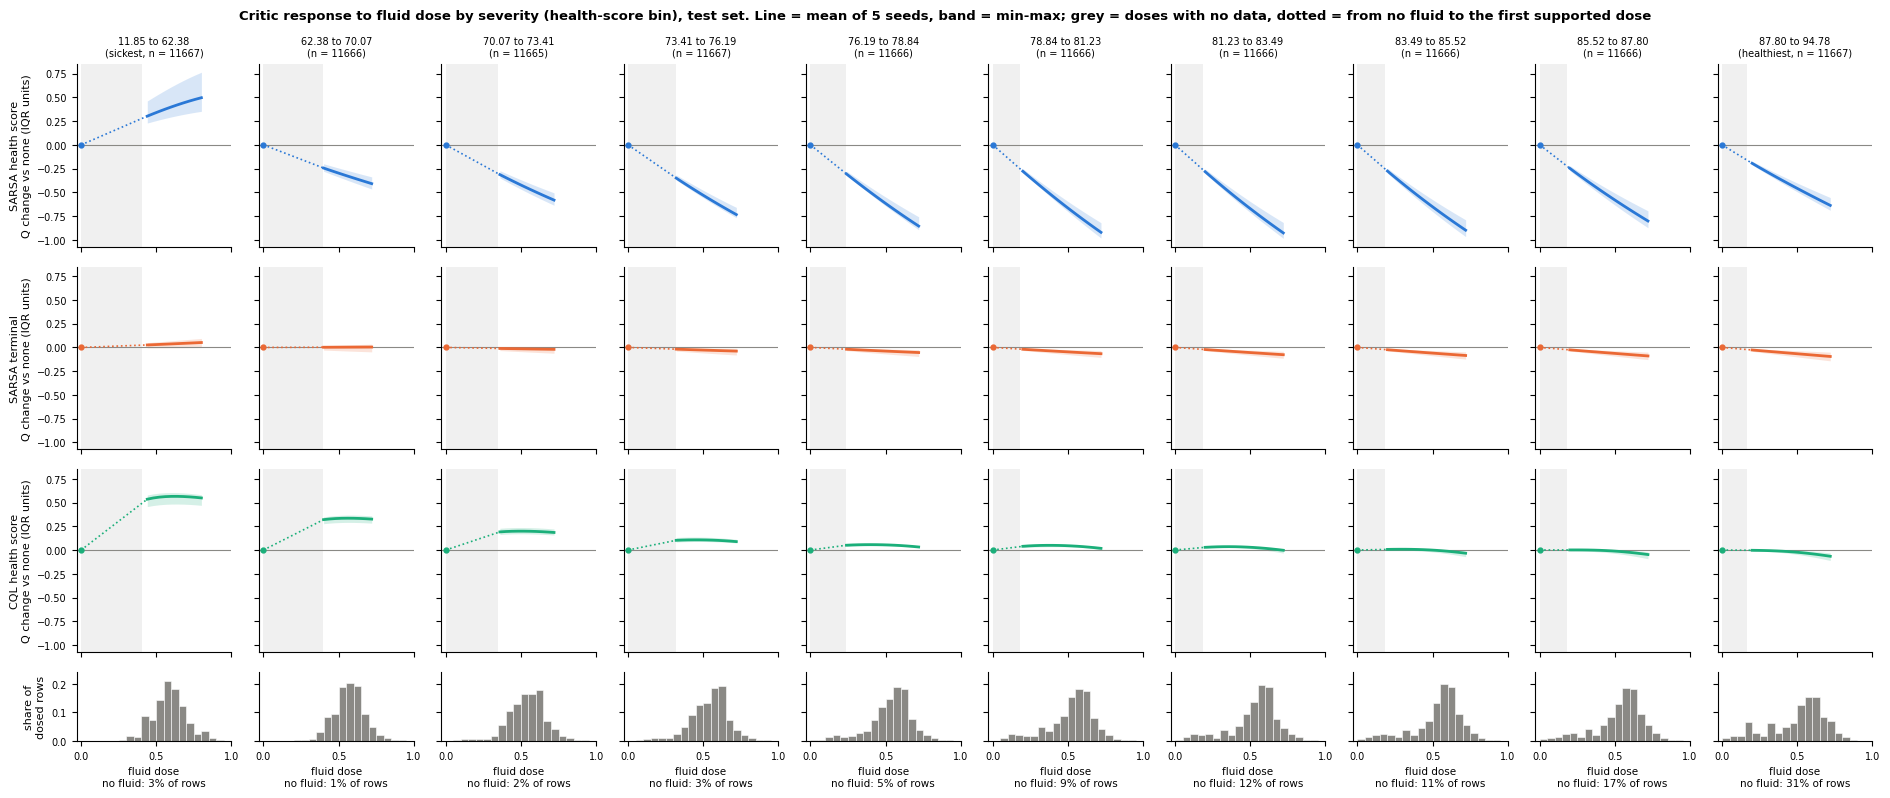

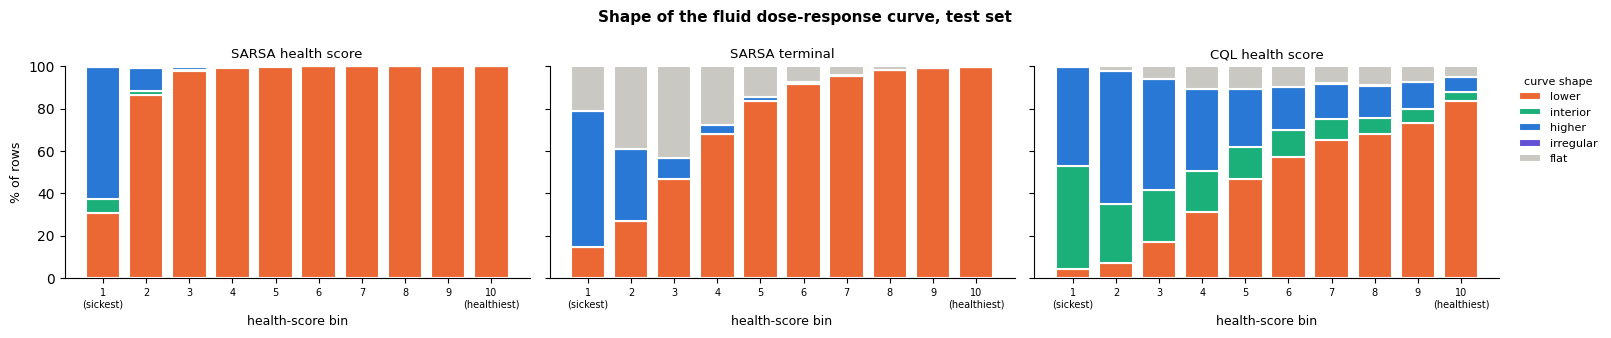

In [9]:
ec.plot_dose_response(res, save_path=os.path.join(critics_dir, "dose_response_test.png"))
ec.plot_shape_fractions(res, save_path=os.path.join(critics_dir, "shape_fractions_test.png"));

  building processors for state seed 0, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
  seed 0: observed returns for 2 critics
  building processors for state seed 1, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_job4167594.pbs-7]  (splits: test, val)
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
using shifted actions for RL dataset
Using terminal reward type
  seed 1: observed returns for 2 critics
  building processors for state seed 2, shared reward [choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181749_006821_

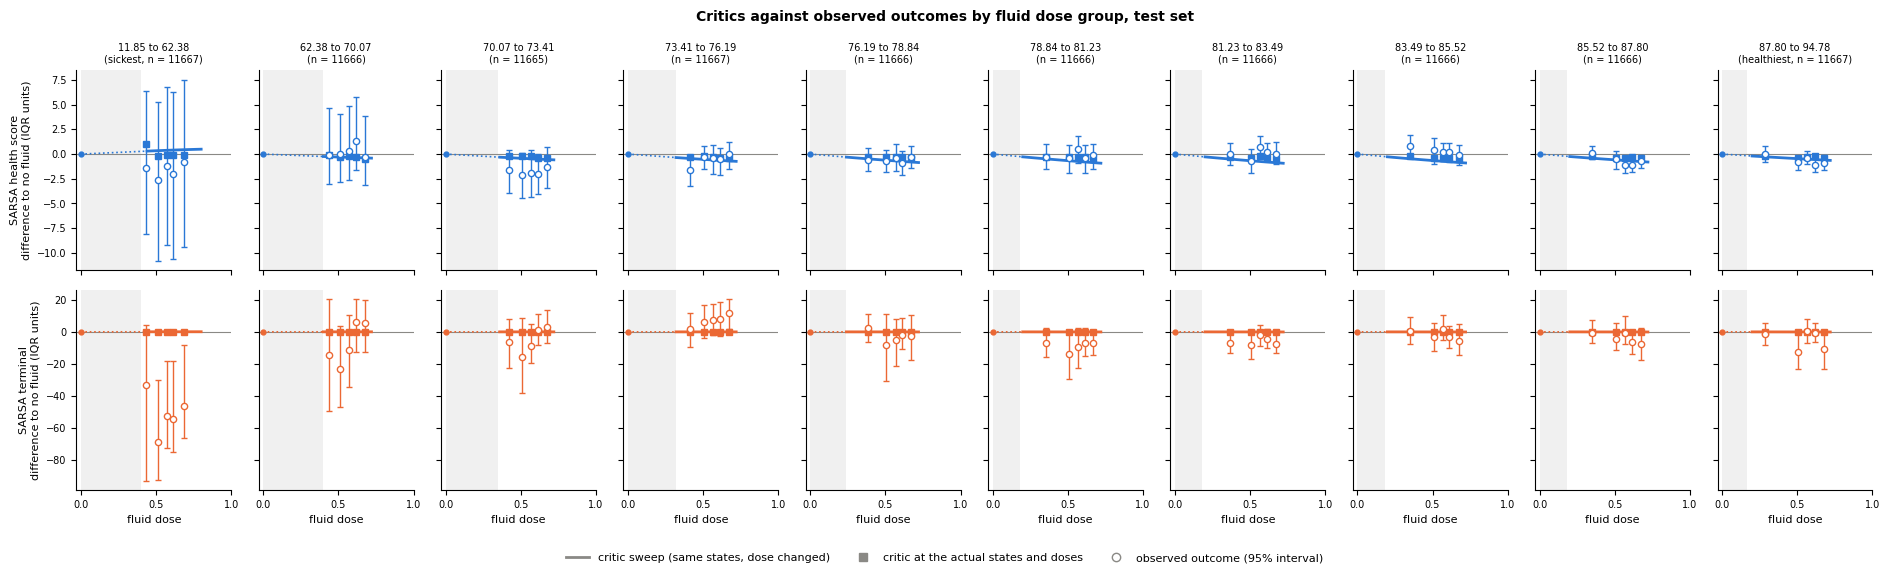

In [10]:
obs = ec.observed_by_dose(res, critics, store, names=["SARSA health score", "SARSA terminal"], ref="SARSA health score")
ec.summarize_observed(obs)
ec.plot_observed_by_dose(res, obs, save_path=os.path.join(critics_dir, "observed_vs_critics_test.png"));

# Vaso

In [15]:
res_vaso = ec.dose_response(critics, store, ref="SARSA health score", split="test", dim=1)
ec.summarize_shapes(res_vaso)

  bins with fewer than 50 nonzero vaso doses (no supported dose): [9]
  seed 0: 116662 rows, 3 critics
  seed 1: 116662 rows, 3 critics
  seed 2: 116662 rows, 3 critics
  seed 3: 116662 rows, 3 critics
  seed 4: 116662 rows, 3 critics


health_score      n n_dosed zero_share     lower  \
                                 range  first   first      first      mean   
critic             bin                                                       
CQL health score   0    11.85 to 62.38  11667    3998   0.657324  0.569521   
                   1    62.38 to 70.07  11666    2163   0.814589  0.772398   
                   2    70.07 to 73.41  11665    1645   0.858980  0.784466   
                   3    73.41 to 76.19  11667    1076   0.907774  0.780389   
                   4    76.19 to 78.84  11666     592   0.949254  0.848431   
                   5    78.84 to 81.23  11666     584   0.949940  0.889714   
                   6    81.23 to 83.49  11666     572   0.950969  0.916218   
                   7    83.49 to 85.52  11666     185   0.984142  0.940374   
                   8    85.52 to 87.80  11666      78   0.993314  0.965215   
                   9    87.80 to 94.78  11667      28   0.997600       NaN   
SARSA health score 0    11.85 to 62.38  11667    3998   0.657324  1.000000   
                   1    62.38 to 70.07  11666    2163   0.814589  1.000000   
                   2    70.07 to 73.41  11665    1645   0.858980  1.000000   
                   3    73.41 to 76.19  11667    1076   0.907774  1.000000   
                   4    76.19 to 78.84  11666     592   0.949254  0.999983   
                   5    78.84 to 81.23  11666     584   0.949940  1.000000   
                   6    81.23 to 83.49  11666     572   0.950969  1.000000   
                   7    83.49 to 85.52  11666     185   0.984142  0.999880   
                   8    85.52 to 87.80  11666      78   0.993314  0.999691   
                   9    87.80 to 94.78  11667      28   0.997600       NaN   
SARSA terminal     0    11.85 to 62.38  11667    3998   0.657324  0.048804   
                   1    62.38 to 70.07  11666    2163   0.814589  0.024859   
                   2    70.07 to 73.41  11665    1645   0.858980  0.026472   
                   3    73.41 to 76.19  11667    1076   0.907774  0.039530   
                   4    76.19 to 78.84  11666     592   0.949254  0.069707   
                   5    78.84 to 81.23  11666     584   0.949940  0.102777   
                   6    81.23 to 83.49  11666     572   0.950969  0.139877   
                   7    83.49 to 85.52  11666     185   0.984142  0.163689   
                   8    85.52 to 87.80  11666      78   0.993314  0.247368   
                   9    87.80 to 94.78  11667      28   0.997600       NaN   

                                            interior                      ...  \
                             min       max      mean       min       max  ...   
critic             bin                                                    ...   
CQL health score   0    0.413731  0.709437  0.383560  0.269907  0.517185  ...   
                   1    0.678639  0.849820  0.169055  0.120607  0.251414  ...   
                   2    0.739477  0.804886  0.130219  0.109301  0.176682  ...   
                   3    0.751093  0.807920  0.097077  0.067284  0.120682  ...   
                   4    0.824704  0.880250  0.087519  0.064461  0.110063  ...   
                   5    0.871507  0.905795  0.079702  0.068318  0.096863  ...   
                   6    0.896280  0.930482  0.064512  0.049031  0.079376  ...   
                   7    0.921910  0.957826  0.047437  0.029316  0.062489  ...   
                   8    0.955340  0.976342  0.033876  0.022373  0.043888  ...   
                   9         NaN       NaN       NaN       NaN       NaN  ...   
SARSA health score 0    1.000000  1.000000  0.000000  0.000000  0.000000  ...   
                   1    1.000000  1.000000  0.000000  0.000000  0.000000  ...   
                   2    1.000000  1.000000  0.000000  0.000000  0.000000  ...   
                   3    1.000000  1.000000  0.000000  0.000000  0.000000  ...   
                   4    0.999914  1.000000  0.000000  0.000000  0.000000  

Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/dose_response_vaso_test.png
Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/shape_fractions_vaso_test.png


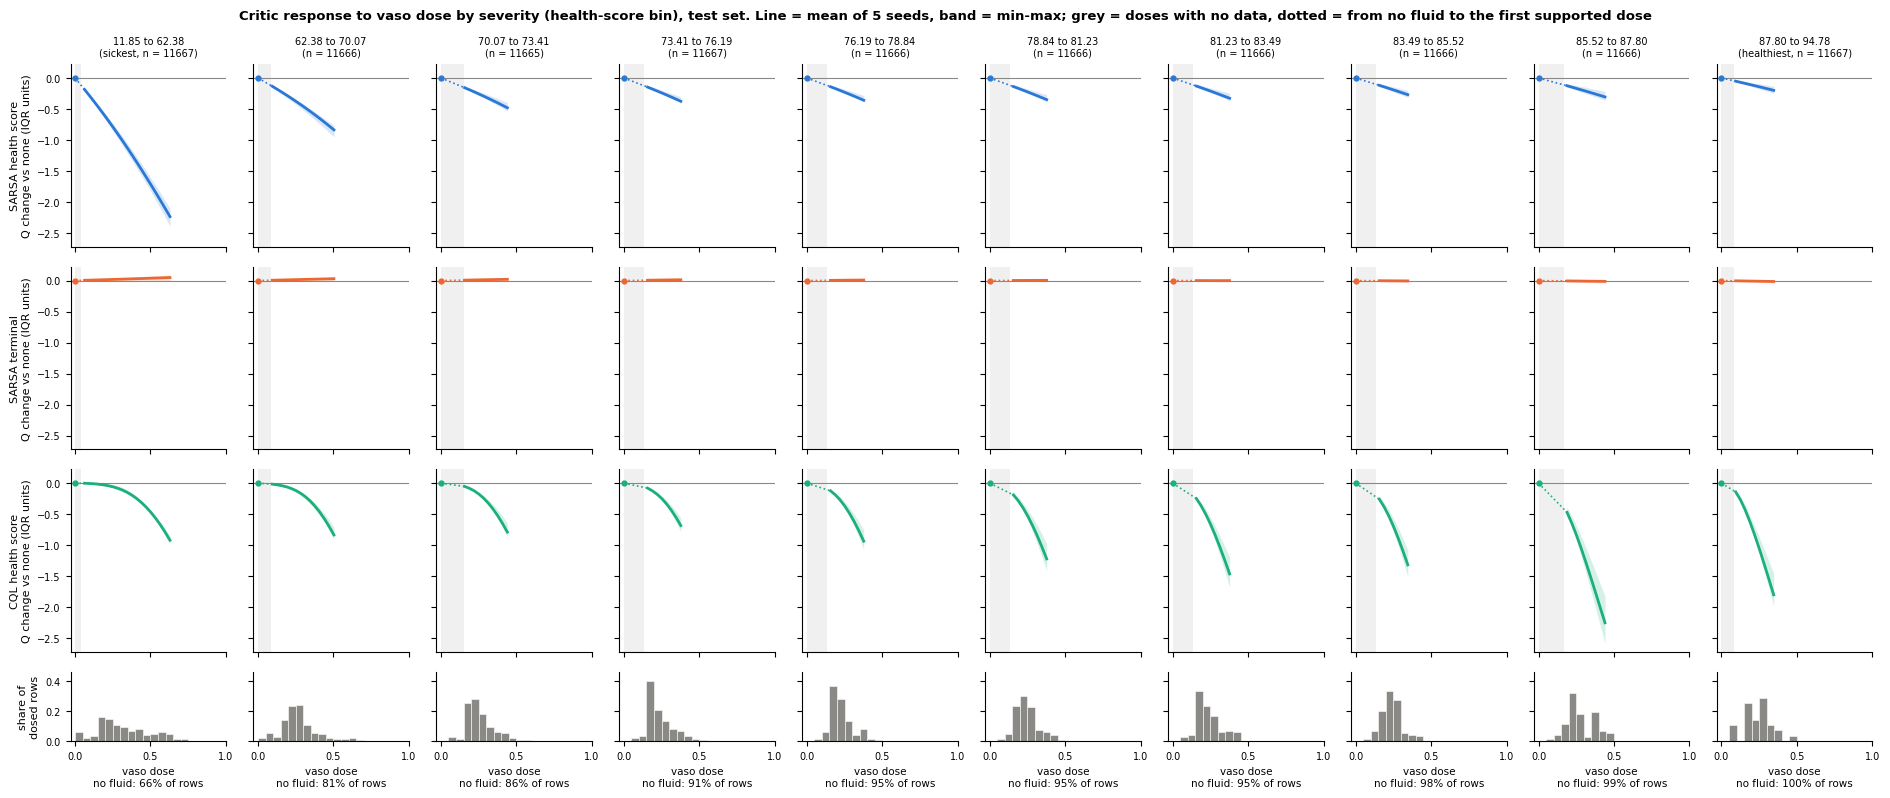

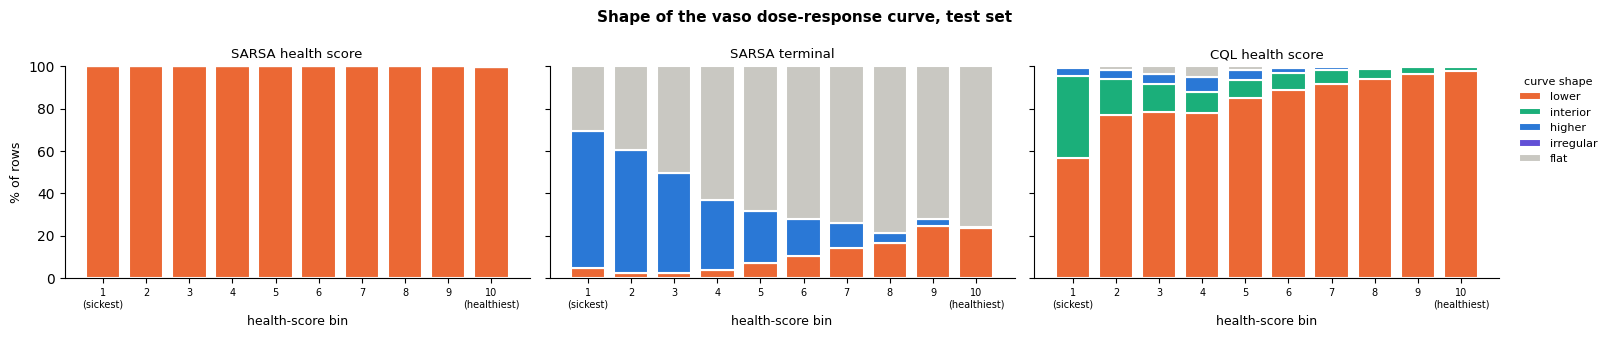

In [12]:
ec.plot_dose_response(res_vaso, save_path=os.path.join(critics_dir, "dose_response_vaso_test.png"));
ec.plot_shape_fractions(res_vaso, save_path=os.path.join(critics_dir, "shape_fractions_vaso_test.png"));

# sensitivity

## row level - sensititivity at any given state

In [18]:
ec.summarize_sensitivity(res, ["SARSA health score", "SARSA terminal"])

critic SARSA health score                     SARSA terminal            \
                      max      mean       min            max      mean   
bin                                                                      
0                1.056288  0.861622  0.751555       0.098479  0.067217   
1                0.527838  0.486429  0.405013       0.049388  0.035696   
2                0.641774  0.591282  0.516611       0.061079  0.031714   
3                0.770178  0.736889  0.661020       0.079814  0.043277   
4                0.894886  0.855370  0.757256       0.094828  0.056154   
5                0.981569  0.921154  0.819666       0.104757  0.067372   
6                0.984406  0.927297  0.817513       0.114175  0.077153   
7                0.965841  0.898418  0.788962       0.122582  0.084948   
8                0.872661  0.801653  0.694327       0.128080  0.089588   
9                0.689038  0.637460  0.554814       0.140990  0.095145   

critic            
             min  
bin               
0       0.041334  
1       0.027529  
2       0.018576  
3       0.020588  
4       0.027721  
5       0.035277  
6       0.042192  
7       0.047356  
8       0.049922  
9       0.049567

In [19]:
ec.sensitivity_ratio(res, "SARSA health score", "SARSA terminal")

,SARSA health score / SARSA terminal: mean,SARSA health score / SARSA terminal: min,SARSA health score / SARSA terminal: max
bin,,,
0,14.231173,7.759056,21.085903
1,14.263723,10.533128,18.826532
2,21.374202,10.507327,27.810435
3,20.103316,9.649689,32.106527
4,17.493953,9.212506,27.316646
5,15.319541,8.761867,23.235224
6,13.298296,7.908796,19.376151
7,11.656468,7.089274,16.660144
8,9.867285,6.093484,13.908369


Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/sensitivity_fluid_test.png


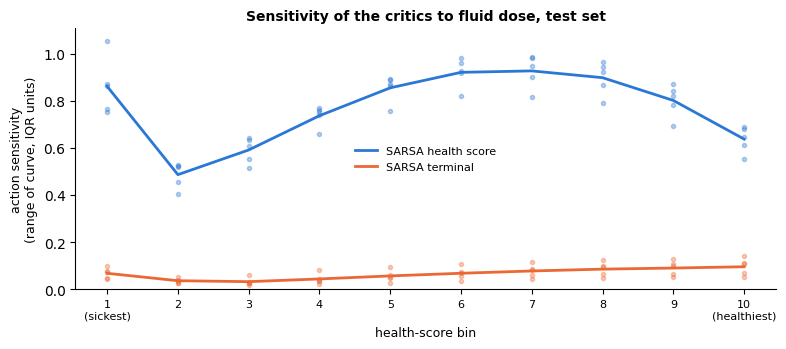

In [20]:
ec.plot_sensitivity(res, ["SARSA health score", "SARSA terminal"], save_path=os.path.join(critics_dir, "sensitivity_fluid_test.png"));

In [21]:
ec.summarize_sensitivity(res_vaso, ["SARSA health score", "SARSA terminal"])

critic SARSA health score                     SARSA terminal            \
                      max      mean       min            max      mean   
bin                                                                      
0                2.387665  2.235954  2.103455       0.092999  0.053953   
1                0.949092  0.836845  0.765949       0.055525  0.033377   
2                0.530038  0.480486  0.395785       0.038883  0.024075   
3                0.402264  0.375758  0.304795       0.028638  0.018845   
4                0.383930  0.358936  0.281527       0.023454  0.017084   
5                0.379357  0.349013  0.272014       0.021426  0.015103   
6                0.364815  0.326759  0.246819       0.027018  0.014445   
7                0.313363  0.269311  0.200868       0.028616  0.012502   
8                0.359897  0.305784  0.216947       0.041418  0.016910   
9                     NaN       NaN       NaN            NaN       NaN   

critic            
             min  
bin               
0       0.015312  
1       0.011256  
2       0.010114  
3       0.007070  
4       0.006643  
5       0.006541  
6       0.007040  
7       0.006457  
8       0.008112  
9            NaN

In [22]:
ec.sensitivity_ratio(res_vaso, "SARSA health score", "SARSA terminal")

,SARSA health score / SARSA terminal: mean,SARSA health score / SARSA terminal: min,SARSA health score / SARSA terminal: max
bin,,,
0,61.328048,23.186586,154.006682
1,36.099922,13.794612,84.316161
2,28.136934,10.178896,49.685897
3,26.522577,10.643022,55.020705
4,26.554870,12.365048,57.797337
5,28.320714,15.753485,57.999298
6,28.064003,12.998773,51.816873
7,28.853631,9.954795,48.531719
8,25.137871,8.012022,44.368333


Saved to /home/jake/Documents/AI_Clinician/models/analysis/critic_dose_response/sensitivity_vaso_test.png


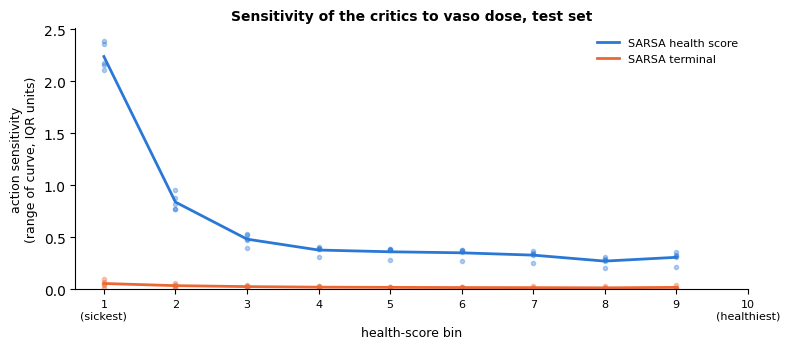

In [23]:
ec.plot_sensitivity(res_vaso, ["SARSA health score", "SARSA terminal"], save_path=os.path.join(critics_dir, "sensitivity_vaso_test.png"));

## curve level sensitivity (this comes from the bin averaged curves)

In [24]:
c = res.curves[res.curves.supported]
(c.groupby(["critic", "seed", "bin"]).delta.agg(lambda x: x.max() - x.min())
  .groupby(["critic", "bin"]).mean().unstack("critic"))

critic,CQL health score,SARSA health score,SARSA terminal
bin,,,
0,0.565183,0.496323,0.052903
1,0.334791,0.408436,0.022797
2,0.198585,0.581405,0.022193
3,0.107198,0.734146,0.038481
4,0.057000,0.854970,0.053783
5,0.049599,0.920970,0.066031
6,0.042160,0.927275,0.076516
7,0.042113,0.898418,0.084787
8,0.051181,0.801653,0.089541


In [25]:
c = res_vaso.curves[res.curves.supported]
(c.groupby(["critic", "seed", "bin"]).delta.agg(lambda x: x.max() - x.min())
  .groupby(["critic", "bin"]).mean().unstack("critic"))

critic,CQL health score,SARSA health score,SARSA terminal
bin,,,
0,0.921615,2.235954,0.049351
1,1.139359,0.966933,0.035141
2,1.445172,0.646259,0.029007
3,1.711782,0.598048,0.025824
4,2.116394,0.568044,0.022162
5,2.521369,0.548719,0.019222
6,2.835849,0.511064,0.016893
7,2.947761,0.459635,0.012756
8,3.205332,0.403204,0.016738
